# Exploratory Data Analysis: S&P 500 Options

**Objective:** Perform comprehensive exploratory data analysis on the SPX options dataset, validating 15:45 EST snapshot selection vs EOD, analyzing temporal quote and expiration distributions, evaluating bid-ask liquidity, and assessing moneyness and maturity coverage.

**Author:** Sérgio da Cunha Sobral  
**Date:** July 2025


### 1. Library Imports


In [1]:
# Manipulação e visualização
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime
import os

### 2. Core Paths & Configuration


In [2]:
DIR_INPUT = "02_data/raw/"
DIR_GRAFICOS = "04_outputs/01_figures/01_eda/"
DIR_TABELAS = "04_outputs/02_tables/01_eda/"
FICHEIRO_INPUT = os.path.join(DIR_INPUT, "InputData_v0.02.parquet")

os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)


### 3. Data Ingestion


In [3]:
# Carregamento do ficheiro parquet
df = pd.read_parquet(FICHEIRO_INPUT)

# Verificação inicial
print(f"✔️ Shape: {df.shape}")
display(df.head())

✔️ Shape: (15144974, 18)


,quote_date,root,expiration,strike,option_type,bid_size_1545,ask_size_1545,bid_1545,ask_1545,underlying_bid_1545,underlying_ask_1545,bid_size_eod,ask_size_eod,bid_eod,ask_eod,underlying_bid_eod,underlying_ask_eod,open_interest
0,2009-01-02,JXA,2009-01-02,750.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0
1,2009-01-02,JXA,2009-01-02,750.0,P,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,1751
2,2009-01-02,JXA,2009-01-02,775.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0
3,2009-01-02,JXA,2009-01-02,775.0,P,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,458
4,2009-01-02,JXA,2009-01-02,800.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0


### 4. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


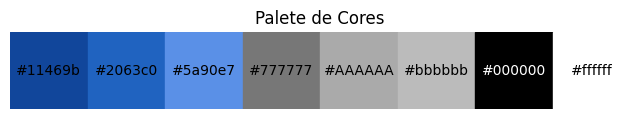

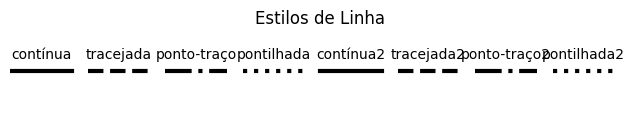

In [4]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"


### 5. Snapshot Selection: 15:45 EST vs End-of-Day (EOD)

**Objective:** Validate that 15:45 EST price quotes are more representative of real market liquidity and true market-clearing prices than final EOD quotes, comparing mid prices and bid-ask spreads.


Correlação entre mid_1545 e mid_eod:
          mid_1545   mid_eod
mid_1545  1.000000  0.998539
mid_eod   0.998539  1.000000
          mid_1545   mid_eod
mid_1545  1.000000  0.998539
mid_eod   0.998539  1.000000


C:\Users\sergi\AppData\Local\Temp\ipykernel_20156\1149441573.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  media_1545 = df.groupby('T_bin')['mid_1545'].mean()
C:\Users\sergi\AppData\Local\Temp\ipykernel_20156\1149441573.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  media_eod = df.groupby('T_bin')['mid_eod'].mean()


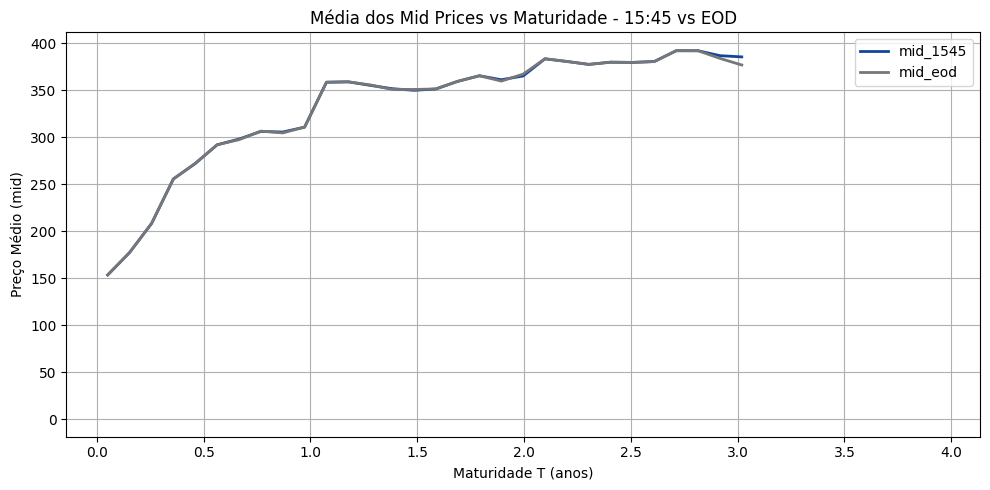

Médias dos spreads:
spread_1545          3.321297
spread_eod           3.584035
spread_under_1545    0.057375
spread_under_eod     6.143699
dtype: float64
spread_1545          3.321297
spread_eod           3.584035
spread_under_1545    0.057375
spread_under_eod     6.143699
dtype: float64


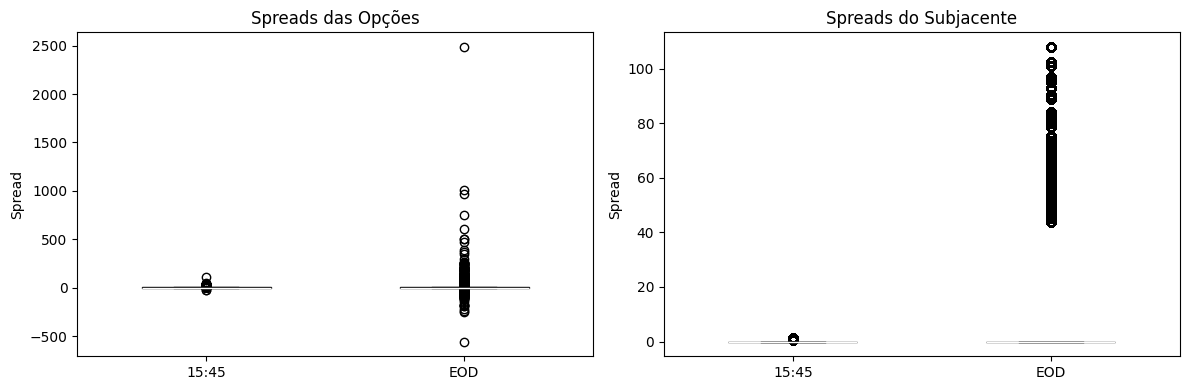

In [5]:
# Análise 1 | Mid prices

# Calcular T_days e T (maturidade em anos)
df["T_days"] = (df["expiration"] - df["quote_date"]).dt.days
df["T"] = df["T_days"] / 365

# mid prices às 15:45 e EOD
df['mid_1545'] = (df['bid_1545'] + df['ask_1545']) / 2
df['mid_eod'] = (df['bid_eod'] + df['ask_eod']) / 2

# Correlação entre mid prices
print("Correlação entre mid_1545 e mid_eod:")
print(df[['mid_1545', 'mid_eod']].corr())

# Gráfico de linha de tendência das médias por bins de maturidade
bins = np.linspace(df['T'].min(), df['T'].max(), 40)
df['T_bin'] = pd.cut(df['T'], bins=bins, include_lowest=True)
media_1545 = df.groupby('T_bin')['mid_1545'].mean()
media_eod = df.groupby('T_bin')['mid_eod'].mean()
centros = [interval.mid for interval in media_1545.index.categories]

plt.figure(figsize=(10, 5))
plt.plot(centros, media_1545.values, label='mid_1545', color=COLOR_AZUL1, linestyle=ESTILOS_LINHA['contínua'], linewidth=2)
plt.plot(centros, media_eod.values, label='mid_eod', color=COLOR_CINZA1, linestyle=ESTILOS_LINHA['contínua'], linewidth=2)
plt.xlabel('Maturidade T (anos)')
plt.ylabel('Preço Médio (mid)')
plt.title('Média dos Mid Prices vs Maturidade - 15:45 vs EOD')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + '00A. Mid Prices analysis.png')
plt.show()



# Análise 2 | Spreads

# Cálculo dos spreads
df['spread_1545'] = df['ask_1545'] - df['bid_1545']
df['spread_eod'] = df['ask_eod'] - df['bid_eod']
df['spread_under_1545'] = df['underlying_ask_1545'] - df['underlying_bid_1545']
df['spread_under_eod'] = df['underlying_ask_eod'] - df['underlying_bid_eod']

# Médias dos spreads
print("Médias dos spreads:")
print(df[['spread_1545', 'spread_eod', 'spread_under_1545', 'spread_under_eod']].mean())

# Boxplots com paleta de cores e exportação
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].boxplot([df['spread_1545'].dropna(), df['spread_eod'].dropna()], patch_artist=True, widths=0.5,
                boxprops=dict(facecolor=COLOR_AZUL1), medianprops=dict(color=COLOR_BRANCO),
                positions=[1,2])
axs[0].set_xticks([1,2])
axs[0].set_xticklabels(['15:45', 'EOD'])
axs[0].set_title('Spreads das Opções')
axs[0].set_ylabel('Spread')

axs[1].boxplot([df['spread_under_1545'].dropna(), df['spread_under_eod'].dropna()], patch_artist=True, widths=0.5,
                boxprops=dict(facecolor=COLOR_AZUL3), medianprops=dict(color=COLOR_BRANCO),
                positions=[1,2])
axs[1].set_xticks([1,2])
axs[1].set_xticklabels(['15:45', 'EOD'])
axs[1].set_title('Spreads do Subjacente')
axs[1].set_ylabel('Spread')

plt.tight_layout()
plt.savefig(DIR_GRAFICOS + '00B. Spreads analysis.png')
plt.show()

**Conclusion on Snapshot Selection:**
Given the high correlation between mid prices and substantially tighter bid-ask spreads at 15:45 EST (particularly on the underlying index), the 15:45 snapshot is selected as the benchmark for all quantitative modeling.


### 6. Temporal Structure of Options

**Objective:** Characterize the temporal distribution of options across quote dates and expiration dates, identifying patterns, cycle seasonality, and maturity profiles.


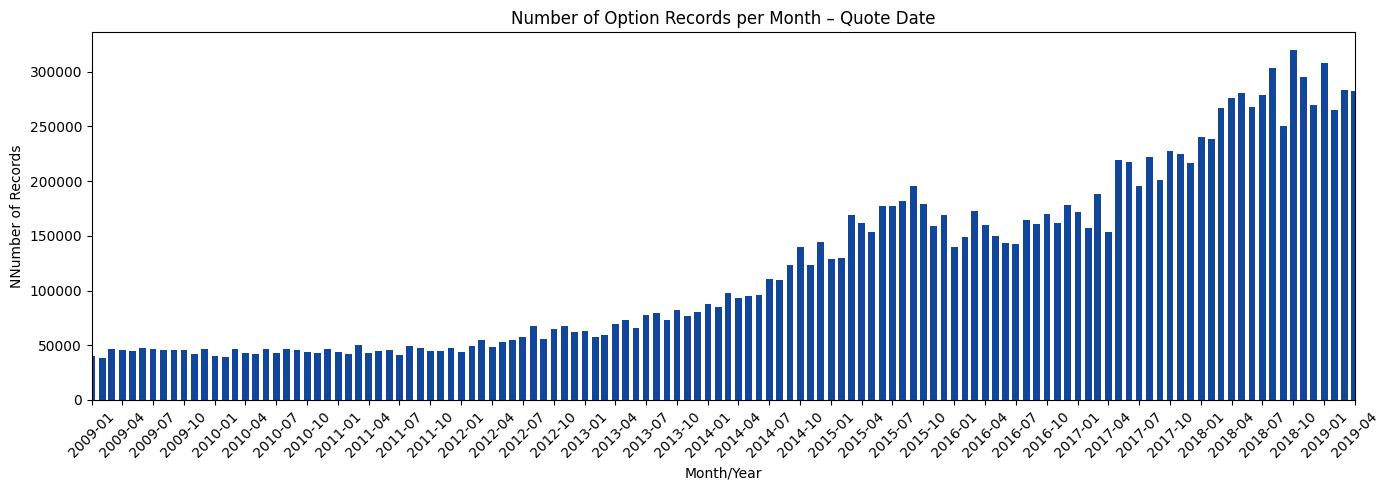

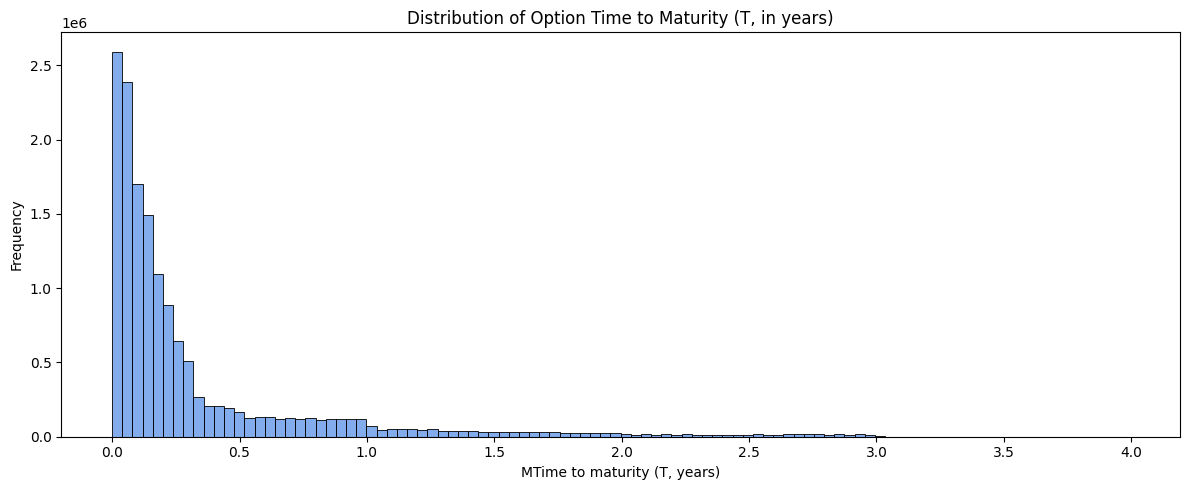

Estatísticas de T (maturidade em anos) - SEM FILTROS:


count    1.514497e+07
mean     3.350809e-01
std      5.059825e-01
min      0.000000e+00
25%      6.027397e-02
50%      1.424658e-01
75%      3.260274e-01
max      3.991781e+00
Name: T, dtype: float64

Estatísticas de T (maturidade em anos) - Liquidez > 0:


count    1.381925e+07
mean     3.540223e-01
std      5.193418e-01
min      0.000000e+00
25%      6.575342e-02
50%      1.561644e-01
75%      3.534247e-01
max      3.991781e+00
Name: T, dtype: float64


Distribuição das opções por maturidade (após filtro de liquidez):
                        Contagem  Percentagem (%)
maturidade_categoria                             
< 1 semana              777016.0             5.62
1 semana a 1 ano      11756466.0            85.07
> 1 ano                1285765.0             9.30
Total                 13819247.0            99.99


In [6]:
# Frequência por mês/ano de quote_date e expiration
df['quote_month'] = df['quote_date'].dt.to_period('M').dt.to_timestamp()
df['expiration_month'] = df['expiration'].dt.to_period('M').dt.to_timestamp()

freq_quote = df['quote_month'].value_counts().sort_index()
freq_exp = df['expiration_month'].value_counts().sort_index()

# --- Quote Date mensal ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(freq_quote.index, freq_quote.values, width=20, color=COLOR_AZUL1)
ax.set_title("Number of Option Records per Month – Quote Date")
ax.set_ylabel("NNumber of Records")
ax.set_xlabel("Month/Year")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
start_date = freq_quote.index.min()
end_date = freq_quote.index.max()
plt.xlim(start_date, end_date)
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "01A. Freq_quote_date_mensal.png")
plt.show()
plt.close()

# --- Expiration Date mensal ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(freq_exp.index, freq_exp.values, width=20, color=COLOR_AZUL2)
ax.set_title("Número de registos por mês - expiration")
ax.set_ylabel("Número de registos")
ax.set_xlabel("Mês/Ano")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
start_date = freq_exp.index.min()
end_date = freq_exp.index.max()
plt.xlim(start_date, end_date)
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "01B. Freq_expiration_date_mensal.png")
plt.close()

# Histograma da maturidade T (em anos) - sem filtros
plt.figure(figsize=(12, 5))
sns.histplot(df["T"], bins=100, color=COLOR_AZUL3, kde=False)
plt.title("Distribution of Option Time to Maturity (T, in years)") # sem filtros aplicados
plt.xlabel("MTime to maturity (T, years)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "01C. Dist_T_maturidade_sem_filtros.png")
plt.show()
plt.close()

print("Estatísticas de T (maturidade em anos) - SEM FILTROS:")
display(df["T"].describe())

# --- Filtro de liquidez: bid_size_1545 > 0 e ask_size_1545 > 0 ---
df_liq = df[(df["bid_size_1545"] > 0) & (df["ask_size_1545"] > 0)].copy()

# --- Quote Date mensal (filtrado) ---
freq_quote_liq = df_liq['quote_month'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(freq_quote_liq.index, freq_quote_liq.values, width=20, color=COLOR_CINZA1)
ax.set_title("Número de registos por mês - quote_date (liquidez > 0)")
ax.set_ylabel("Número de registos")
ax.set_xlabel("Mês/Ano")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
start_date = freq_quote_liq.index.min()
end_date = freq_quote_liq.index.max()
plt.xlim(start_date, end_date)
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "02A. Freq_quote_date_mensal_liquido.png")
plt.close()

# --- Expiration Date mensal (filtrado) ---
freq_exp_liq = df_liq['expiration_month'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(freq_exp_liq.index, freq_exp_liq.values, width=20, color=COLOR_CINZA2)
ax.set_title("Número de registos por mês - expiration (liquidez > 0)")
ax.set_ylabel("Número de registos")
ax.set_xlabel("Mês/Ano")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
start_date = freq_exp_liq.index.min()
end_date = freq_exp_liq.index.max()
plt.xlim(start_date, end_date)
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "02B. Freq_expiration_date_mensal_liquido.png")
plt.close()

# --- Histograma da maturidade T (em anos) - filtrado ---
plt.figure(figsize=(12, 5))
sns.histplot(df_liq["T"], bins=100, color=COLOR_CINZA3, kde=False)
plt.title("Distribuição da maturidade (T, em anos) - Liquidez > 0")
plt.xlabel("Maturidade (T, anos)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "02C. Dist_T_maturidade_liquido.png")
plt.close()

print("Estatísticas de T (maturidade em anos) - Liquidez > 0:")
display(df_liq["T"].describe())

# --- Distribuição das maturidades após filtro de liquidez ---
bins = [0, 7, 365, np.inf]
labels = ['< 1 semana', '1 semana a 1 ano', '> 1 ano']
df_liq['maturidade_categoria'] = pd.cut(df_liq['T_days'], bins=bins, labels=labels, right=False)
contagem = df_liq['maturidade_categoria'].value_counts().reindex(labels)
percentagens = (contagem / contagem.sum() * 100).round(2)
tabela = pd.DataFrame({'Contagem': contagem, 'Percentagem (%)': percentagens})
# Adicionar linha de total
tabela.loc['Total'] = [contagem.sum(), percentagens.sum()]
print('\nDistribuição das opções por maturidade (após filtro de liquidez):')
print(tabela)

### 7. Liquidity Analysis: Bid & Ask Sizes

**Objective:** Examine contract liquidity via quote depth (bid/ask sizes) across maturity horizons.


In [7]:
# 🟨 1. Histogramas das sizes
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["bid_size_1545"], bins=50, ax=axs[0], color=COLOR_AZUL3)  # azul3
# Usar azul3 para bid_size_1545
axs[0].set_title("Histograma - bid_size_1545")
axs[0].set_xlabel("Bid Size (15:45)")
sns.histplot(df["ask_size_1545"], bins=50, ax=axs[1], color=COLOR_CINZA1)  # cinza1
# Usar cinza1 para ask_size_1545
axs[1].set_title("Histograma - ask_size_1545")
axs[1].set_xlabel("Ask Size (15:45)")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "03A. Hist_BidAskSize_1545.png")
plt.close()

# 🟨 2. Linhas das médias das sizes por bins de maturidade (T)
# Definir bins de maturidade
bins_T = np.linspace(df["T"].min(), df["T"].max(), 40)
df["T_bin"] = pd.cut(df["T"], bins=bins_T, include_lowest=True)

# Média do bid_size_1545 por bin de T
media_bid = df.groupby("T_bin", observed=False)["bid_size_1545"].mean()
centros = [interval.mid for interval in media_bid.index.categories]
plt.figure(figsize=(10, 5))
plt.plot(centros, media_bid.values, color=COLOR_AZUL3, label="Média Bid Size", linewidth=2)
plt.title("Média do Bid Size vs Maturidade (T)")
plt.xlabel("Maturidade (T, anos)")
plt.ylabel("Média Bid Size (15:45)")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "03B.4. BidSize_vs_T_media.png")
plt.close()

# Média do ask_size_1545 por bin de T
media_ask = df.groupby("T_bin", observed=False)["ask_size_1545"].mean()
centros = [interval.mid for interval in media_ask.index.categories]
plt.figure(figsize=(10, 5))
plt.plot(centros, media_ask.values, color=COLOR_CINZA1, label="Média Ask Size", linewidth=2)
plt.title("Média do Ask Size vs Maturidade (T)")
plt.xlabel("Maturidade (T, anos)")
plt.ylabel("Média Ask Size (15:45)")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "03C. AskSize_vs_T_media.png")
plt.close()

# 🟨 3. Tabela resumo de liquidez por tipo de opção
tipos = ["C", "P"]
linhas = []
for tipo in tipos:
    df_tipo = df[df["option_type"] == tipo]
    total = len(df_tipo)
    ask_pos = (df_tipo["ask_size_1545"] > 0).sum()
    bid_pos = (df_tipo["bid_size_1545"] > 0).sum()
    ambos_pos = ((df_tipo["ask_size_1545"] > 0) & (df_tipo["bid_size_1545"] > 0)).sum()
    linhas.append([tipo, total, ask_pos, ask_pos/total*100, bid_pos, bid_pos/total*100, ambos_pos, ambos_pos/total*100])
# Total geral
total = len(df)
ask_pos = (df["ask_size_1545"] > 0).sum()
bid_pos = (df["bid_size_1545"] > 0).sum()
ambos_pos = ((df["ask_size_1545"] > 0) & (df["bid_size_1545"] > 0)).sum()
linhas.append(["Total", total, ask_pos, ask_pos/total*100, bid_pos, bid_pos/total*100, ambos_pos, ambos_pos/total*100])
tabela = pd.DataFrame(linhas, columns=["Tipo", "N", "Ask > 0", "% Ask > 0", "Bid > 0", "% Bid > 0", "Ambos > 0", "% Ambos > 0"])
print("\nResumo de liquidez por tipo de opção:")
print(tabela.round(2))


Resumo de liquidez por tipo de opção:
    Tipo         N   Ask > 0  % Ask > 0   Bid > 0  % Bid > 0  Ambos > 0  \
0      C   7572494   7523783      99.36   7081299      93.51    7081295   
1      P   7572480   7502017      99.07   6737955      88.98    6737952   
2  Total  15144974  15025800      99.21  13819254      91.25   13819247   

   % Ambos > 0  
0        93.51  
1        88.98  
2        91.25  


### 8. Progressive Impact of Filtering Stages


In [8]:
filtros = []
df0 = df.copy()
n0_c = (df0["option_type"] == "C").sum()
n0_p = (df0["option_type"] == "P").sum()
n0 = len(df0)
filtros.append(["Inicial", n0_c, n0_p, n0, 100.0])
# 1. Remoção de ilíquidas (ask e bid size > 0)
df1 = df0[(df0["ask_size_1545"] > 0) & (df0["bid_size_1545"] > 0)]
n1_c = (df1["option_type"] == "C").sum()
n1_p = (df1["option_type"] == "P").sum()
n1 = len(df1)
filtros.append(["Liquidez (ask & bid > 0)", n1_c, n1_p, n1, n1/n0*100])
# 2. Remoção de maturidades < 1 semana
df2 = df1[df1["T_days"] >= 7]
n2_c = (df2["option_type"] == "C").sum()
n2_p = (df2["option_type"] == "P").sum()
n2 = len(df2)
filtros.append(["T >= 1 semana", n2_c, n2_p, n2, n2/n0*100])
# 3. Remoção de maturidades >= 2 anos
df3 = df2[df2["T_days"] < 730]
n3_c = (df3["option_type"] == "C").sum()
n3_p = (df3["option_type"] == "P").sum()
n3 = len(df3)
filtros.append(["T < 2 anos", n3_c, n3_p, n3, n3/n0*100])
# 4. Remoção de maturidades > 1 ano
df4 = df3[df3["T_days"] <= 365]
n4_c = (df4["option_type"] == "C").sum()
n4_p = (df4["option_type"] == "P").sum()
n4 = len(df4)
filtros.append(["T <= 1 ano", n4_c, n4_p, n4, n4/n0*100])
# Tabela resumo
tabela_filtros = pd.DataFrame(filtros, columns=["Filtro", "Calls", "Puts", "Total", "% do Inicial"] )
print("\nEfeito progressivo dos filtros no número de opções:")
print(tabela_filtros.round(2))


Efeito progressivo dos filtros no número de opções:
                     Filtro    Calls     Puts     Total  % do Inicial
0                   Inicial  7572494  7572480  15144974        100.00
1  Liquidez (ask & bid > 0)  7081295  6737952  13819247         91.25
2             T >= 1 semana  6617978  6424253  13042231         86.12
3                T < 2 anos  6434447  6241311  12675758         83.70
4                T <= 1 ano  5980004  5783994  11763998         77.68


#### Filtering Conclusion:
The filtering process ensures a robust dataset of liquid contracts with valid maturities, preserving over 77.7% of the original universe while removing illiquid artifacts.


In [9]:
# Definir dataframe filtrado para análises seguintes (liquidez e 1 semana <= T <= 1 ano)
df_analise = df[(df["ask_size_1545"] > 0) & (df["bid_size_1545"] > 0) & (df["T_days"] >= 7) & (df["T_days"] <= 365)].copy()
print(f"Shape do dataframe filtrado para análise: {df_analise.shape}")

Shape do dataframe filtrado para análise: (11763998, 29)


### 9. Sample Distributions (Prices, Strikes, Maturity & Log-Moneyness)

**Objective:** Explore the empirical distributions of option mid prices, maturities in days ($T$), strikes ($K$), underlying spot ($S$), and log-moneyness ($m = \ln(K/S)$).


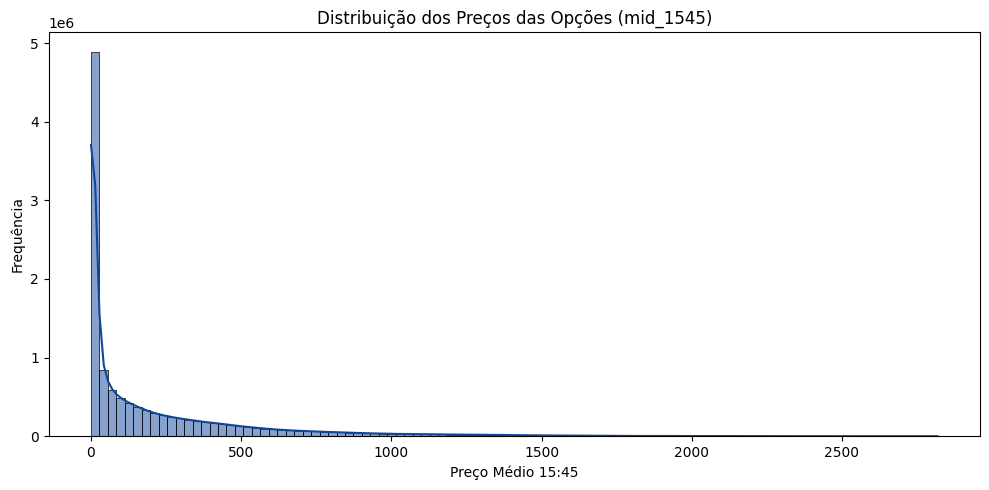

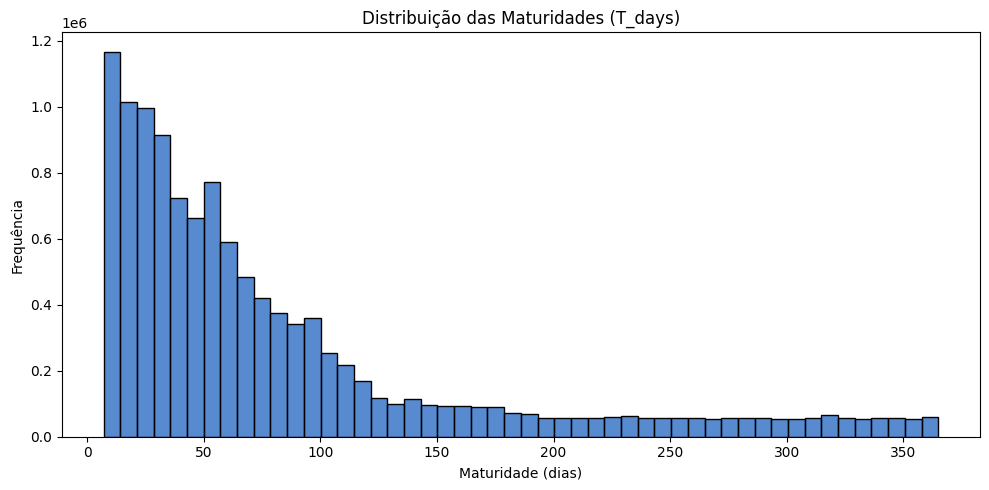

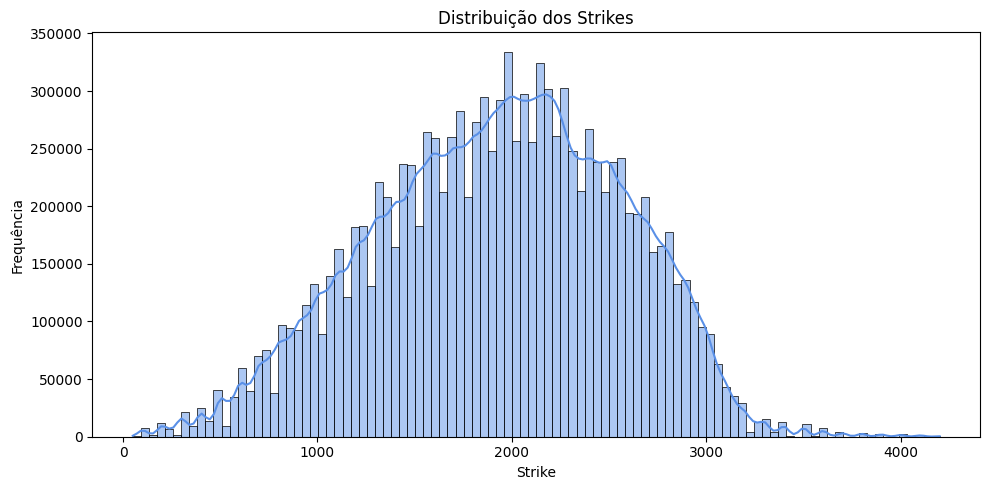

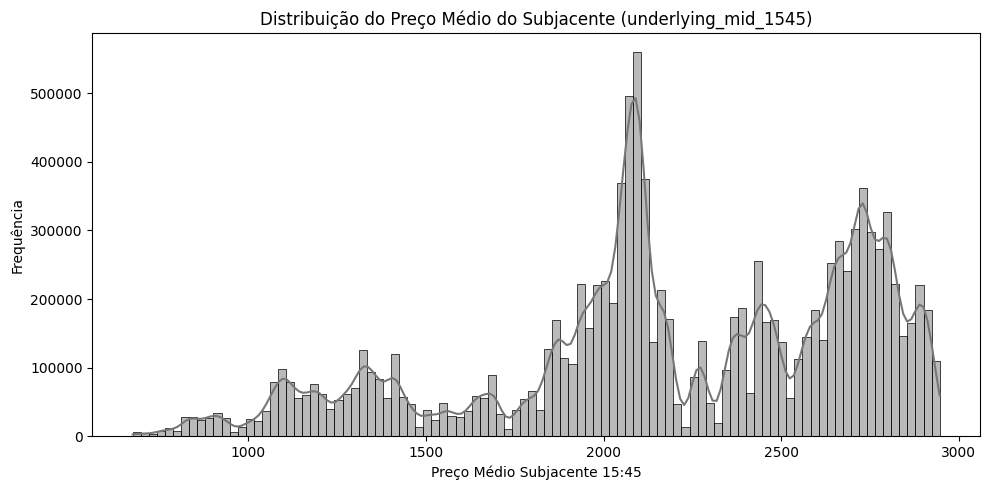

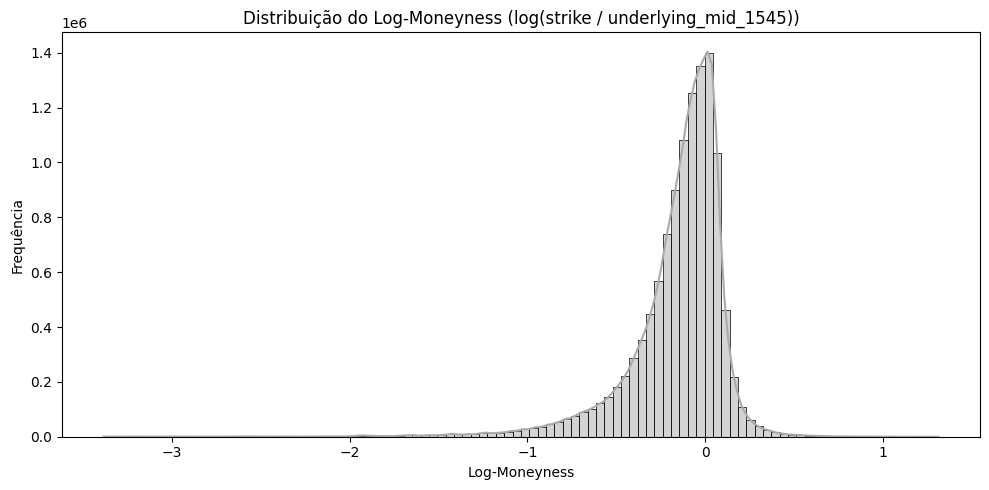

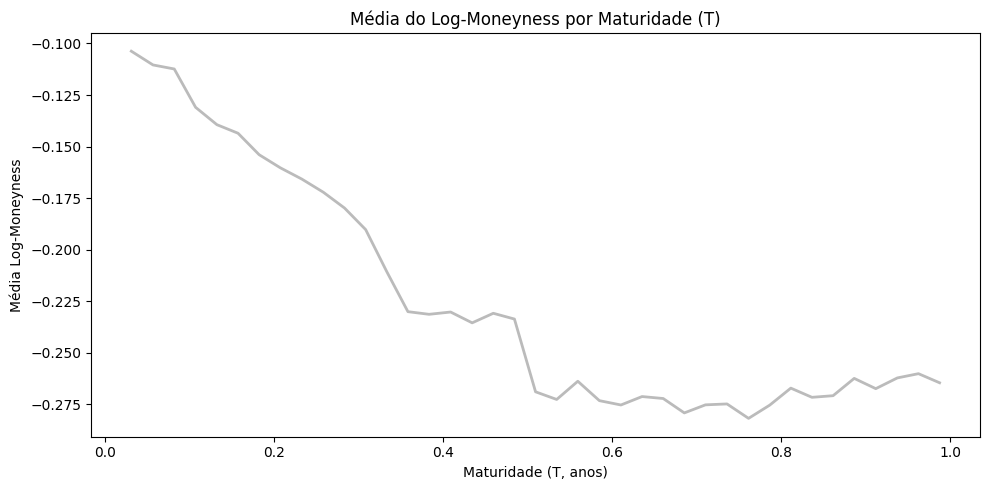

Estatísticas dos Preços (mid_1545):


count    1.176400e+07
mean     2.103434e+02
std      3.232736e+02
min      2.000000e-02
25%      4.050000e+00
50%      6.250000e+01
75%      2.896000e+02
max      2.818600e+03
Name: mid_1545, dtype: float64


Estatísticas das Maturidades (T_days):


count    1.176400e+07
mean     8.286513e+01
std      8.320731e+01
min      7.000000e+00
25%      2.700000e+01
50%      5.300000e+01
75%      1.010000e+02
max      3.650000e+02
Name: T_days, dtype: float64


Estatísticas dos Strikes:


count    1.176400e+07
mean     1.929881e+03
std      6.303563e+02
min      5.000000e+01
25%      1.480000e+03
50%      1.965000e+03
75%      2.400000e+03
max      4.200000e+03
Name: strike, dtype: float64


Estatísticas do Preço Médio do Subjacente (underlying_mid_1545):


count    1.176400e+07
mean     2.189577e+03
std      5.285124e+02
min      6.752100e+02
25%      1.939830e+03
50%      2.164680e+03
75%      2.667940e+03
max      2.945825e+03
Name: underlying_mid_1545, dtype: float64


Estatísticas do Log-Moneyness:


count    1.176400e+07
mean    -1.584071e-01
std      2.829452e-01
min     -3.382974e+00
25%     -2.468199e-01
50%     -9.384964e-02
75%      1.060188e-02
max      1.309022e+00
Name: log_moneyness, dtype: float64

In [10]:
# Análise dos preços das opções, maturidades e strikes usando df_analise
plt.figure(figsize=(10, 5))
sns.histplot(df_analise["mid_1545"], bins=100, color=COLOR_AZUL1, kde=True)
plt.title("Distribuição dos Preços das Opções (mid_1545)")
plt.xlabel("Preço Médio 15:45")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04A. Dist_PrecoMid_1545.png")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(df_analise["T_days"], bins=50, color=COLOR_AZUL2, kde=False)
plt.title("Distribuição das Maturidades (T_days)")
plt.xlabel("Maturidade (dias)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04B. Dist_Maturidade_T_days.png")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(df_analise["strike"], bins=100, color=COLOR_AZUL3, kde=True)
plt.title("Distribuição dos Strikes")
plt.xlabel("Strike")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04C. Dist_Strike.png")
plt.show()

# --- Novo: Análise do preço médio do subjacente (underlying_mid_1545) ---
df_analise["underlying_mid_1545"] = (df_analise["underlying_bid_1545"] + df_analise["underlying_ask_1545"]) / 2
plt.figure(figsize=(10, 5))
sns.histplot(df_analise["underlying_mid_1545"], bins=100, color=COLOR_CINZA1, kde=True)
plt.title("Distribuição do Preço Médio do Subjacente (underlying_mid_1545)")
plt.xlabel("Preço Médio Subjacente 15:45")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04D. Dist_UnderlyingMid_1545.png")
plt.show()

# --- Novo: Log-moneyness com underlying_mid_1545 ---
df_analise["log_moneyness"] = np.log(df_analise["strike"] / df_analise["underlying_mid_1545"])

# Histograma da distribuição global do log-moneyness
plt.figure(figsize=(10, 5))
sns.histplot(df_analise["log_moneyness"], bins=100, color=COLOR_CINZA2, kde=True)
plt.title("Distribuição do Log-Moneyness (log(strike / underlying_mid_1545))")
plt.xlabel("Log-Moneyness")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04E. Dist_LogMoneyness.png")
plt.show()

# Média de log-moneyness por bin de T
bins_T = np.linspace(df_analise["T"].min(), df_analise["T"].max(), 40)
df_analise["T_bin"] = pd.cut(df_analise["T"], bins=bins_T, include_lowest=True)
media_logmon = df_analise.groupby("T_bin", observed=False)["log_moneyness"].mean()
centros = [interval.mid for interval in media_logmon.index.categories]
plt.figure(figsize=(10, 5))
plt.plot(centros, media_logmon.values, color=COLOR_CINZA3, linewidth=2)
plt.title("Média do Log-Moneyness por Maturidade (T)")
plt.xlabel("Maturidade (T, anos)")
plt.ylabel("Média Log-Moneyness")
plt.tight_layout()
plt.savefig(DIR_GRAFICOS + "04F. Media_LogMoneyness_vs_T.png")
plt.show()

# Estatísticas descritivas
print("Estatísticas dos Preços (mid_1545):")
display(df_analise["mid_1545"].describe())
print("\nEstatísticas das Maturidades (T_days):")
display(df_analise["T_days"].describe())
print("\nEstatísticas dos Strikes:")
display(df_analise["strike"].describe())
print("\nEstatísticas do Preço Médio do Subjacente (underlying_mid_1545):")
display(df_analise["underlying_mid_1545"].describe())
print("\nEstatísticas do Log-Moneyness:")
display(df_analise["log_moneyness"].describe())